# Transcription and Searching Transcripts

A journalist searches the radio archive for the interview in which a guest mentioned a local
politician by name. Labels such as "speech" narrow the search to the talk, but only the words
themselves answer the question. Once transcribed, an hour of broadcast enters the inverted index
like any document. This notebook follows the book section *Transcription*. It transcribes the
three LibriVox readings of the chapter with Whisper and with Qwen3-ASR, an LLM-based recognizer,
measures word and character error rates against the reference transcripts, and looks at the words
that matter most for search: names. At the end, a phonetic index finds names that both recognizers
misspelled, and a hit leads to the moment in the recording.

**Learning goals:**
- See the input of a modern recognizer: a log mel spectrogram of a 30-second window
- Transcribe speech with Whisper and Qwen3-ASR and compare the two
- Align a transcript with a reference by edit distance and compute WER and CER
- Check whether the names in a recording survive transcription, and bias a recognizer with hotwords
- Search transcripts with timestamps, exactly and phonetically

**Prerequisites:** demo ch11-01 (mel scale, log mel spectrum); edit distance and Soundex (demo
ch03-04)

**Data:** the three LibriVox readings of the chapter (librosa examples, downloaded on the first run)
and their reference transcripts from the LibriSpeech corpus in `data/ch11/librispeech_references.json`.
The models Whisper small (about 1 GB) and Qwen3-ASR-0.6B (about 1.6 GB) are downloaded from Hugging
Face on first use and run on a CPU; the notebook takes a few minutes.

## Setup

In [1]:
import json
import re
from collections import Counter, defaultdict

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio
from pathlib import Path

from shared.display import print_table, display_md
from shared.text import soundex
from ch11_audio import CLIPS, ASR_SR, load, credits, Whisper, QwenASR

READINGS = ["libri1", "libri2", "libri3"]
refs = json.loads(Path("data/ch11/librispeech_references.json").read_text(encoding="utf-8"))
speech = {n: load(n, ASR_SR) for n in READINGS}         # both recognizers expect 16 kHz

## 1. The Input of Whisper

Whisper resamples the audio to 16 kHz, cuts it into windows of 30 seconds, and turns each window
into 80 mel bands computed from frames of 25 ms with a hop of 10 ms. The log mel spectrogram brings
recordings with different sampling rates into one format and shrinks 480,000 samples to 3,000
frames of 80 values.

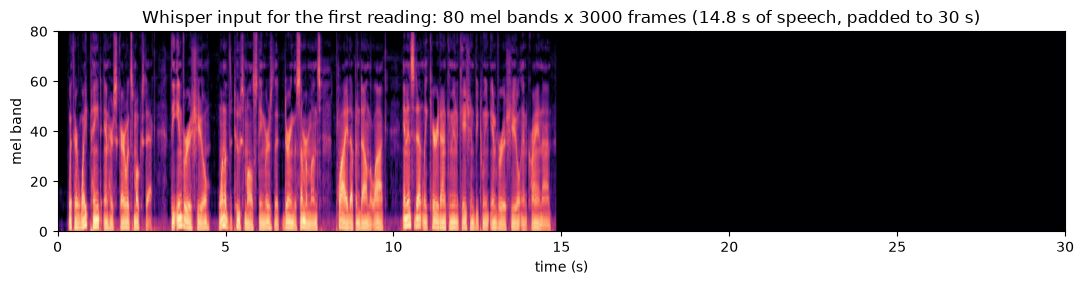

In [2]:
whisper = Whisper()
feats = whisper.proc(speech["libri1"], sampling_rate=ASR_SR, return_tensors="np").input_features[0]

fig, ax = plt.subplots(figsize=(13, 2.6))
ax.imshow(feats, origin="lower", aspect="auto", cmap="magma", extent=(0, feats.shape[1] / 100, 0, feats.shape[0]))
ax.set(xlabel="time (s)", ylabel="mel band",
       title=f"Whisper input for the first reading: {feats.shape[0]} mel bands x {feats.shape[1]} frames "
             f"({len(speech['libri1']) / ASR_SR:.1f} s of speech, padded to 30 s)")
plt.show()

## 2. Two Recognizers on Three Readings

Whisper small has 244 million parameters and was trained on 680,000 hours of weakly labeled audio.
Qwen3-ASR-0.6B connects an audio encoder to a language model with 0.6 billion parameters; it
identifies the language itself. We transcribe the three readings with both and show the
LibriSpeech reference next to them.

In [3]:
qwen = QwenASR()

hyp = {"Whisper": {}, "Qwen3-ASR": {}}
for n in READINGS:
    hyp["Whisper"][n] = whisper.transcribe(speech[n], language="en")
    hyp["Qwen3-ASR"][n] = qwen.transcribe(speech[n])["transcription"]

display_md("\n\n".join(
    f"**{CLIPS[n][0]}**\n\n- *Reference:* {refs[n]['text'].capitalize()}\n"
    + "\n".join(f"- *{rec}:* {hyp[rec][n]}" for rec in hyp)
    for n in READINGS))

**LibriVox reading 1 (The Ashiel Mystery)**

- *Reference:* With her white paint and her scarlet smokestack the inverashiel one of the two small steamers that during the summer months plied up and down the loch and incidentally carried on communication between inverashiel and crianan
- *Whisper:* With her white paint and her scarlet smokestack, the Inverashiel, one of the two small steamers that during the summer months, plied up and down the lock, and incidentally carried on communication between Inverashiel and Cryonon.
- *Qwen3-ASR:* With her white paint and her scarlet smokestack, the Inverishield, one of the two small steamers that during the summer months plied up and down the lock, and incidentally carried on communication between Inverishield and Cryonon.

**LibriVox reading 2 (The Age of Chivalry)**

- *Reference:* The adventure of the cart it befell in the month of may queen guenever called to her knights of the table round and gave them warning that early upon the morrow she would ride a maying into the woods and fields beside westminster
- *Whisper:* The Adventure of the Cart. It befell in the month of May. Queen Gwenevere called to her knights of the table round and gave them warning that early upon the morrow she would ride a maying into the woods and fields beside Westminster.
- *Qwen3-ASR:* The Adventure of the Cart. It befell in the month of May. Queen Guenever called to her knights of the table round and gave them warning that early upon the morrow she would ride a maying into the woods and fields beside Westminster.

**LibriVox reading 3 (Northanger Abbey)**

- *Reference:* Missus allen said catherine the next morning will there be any harm in my calling on miss tilney today i shall not be easy till i have explained everything go by all means my dear only put on a white gown miss tilney always wears white
- *Whisper:* Mrs. Allen," said Chathrin the next morning,--"will there be any harm in my calling on Miss Tilney to-day? I shall not be easy till I have explained everything." Go, by all means, my dear, only put on a white gown. Miss Tilney always wears white."
- *Qwen3-ASR:* Missus Allan said, "Catherine, the next morning, will there be any harm in my calling on Miss Tilney today? I shall not be easy till I have explained everything." Go by all means, my dear. Only put on a white gown. Miss Tilney always wears white.

Both transcripts read well. The reference is written in upper case without punctuation, as in the
corpus, so before comparing we bring both sides into one normal form: lower case, no punctuation,
and a few spelling rules for abbreviations.

In [4]:
RULES = {"mrs": "missus", "mr": "mister", "to-day": "today"}

def normalize(text):
    words = re.sub(r"[^\w\s'-]", " ", text.lower()).split()
    words = [RULES.get(w.strip("-"), w) for w in words]
    return " ".join(words).replace("-", " ").split()

print_table([[n, " ".join(normalize(hyp["Whisper"][n]))[:110] + " ..."] for n in READINGS],
            headers=["Reading", "Whisper, normalized"])

| Reading   | Whisper, normalized                                                                                                |
|:----------|:-------------------------------------------------------------------------------------------------------------------|
| libri1    | with her white paint and her scarlet smokestack the inverashiel one of the two small steamers that during the  ... |
| libri2    | the adventure of the cart it befell in the month of may queen gwenevere called to her knights of the table rou ... |
| libri3    | missus allen said chathrin the next morning will there be any harm in my calling on miss tilney today i shall  ... |

## 3. Word and Character Error Rates

The hypothesis and the reference are aligned with the minimal number of edits: substitutions,
deletions, and insertions of words. The word error rate divides the edits by the length $N$ of the
reference:

$$
\text{WER} = \frac{S + D + I}{N}
$$

The character error rate (CER) applies the same formula to characters. The alignment is the edit
distance of demo ch03-04, computed on words instead of letters, with a backtrace that records which
edit was made where.

In [5]:
def align(ref, hyp):
    """Minimal edit alignment of two sequences: a list of (op, ref_item, hyp_item), op in = S D I."""
    n, m = len(ref), len(hyp)
    D = np.zeros((n + 1, m + 1), dtype=int)
    D[:, 0], D[0, :] = np.arange(n + 1), np.arange(m + 1)
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            D[i, j] = min(D[i - 1, j - 1] + (ref[i - 1] != hyp[j - 1]), D[i - 1, j] + 1, D[i, j - 1] + 1)
    ops, i, j = [], n, m
    while i > 0 or j > 0:                               # walk back from the end
        if i > 0 and j > 0 and D[i, j] == D[i - 1, j - 1] + (ref[i - 1] != hyp[j - 1]):
            ops.append(("=" if ref[i - 1] == hyp[j - 1] else "S", ref[i - 1], hyp[j - 1]))
            i, j = i - 1, j - 1
        elif i > 0 and D[i, j] == D[i - 1, j] + 1:
            ops.append(("D", ref[i - 1], ""))
            i -= 1
        else:
            ops.append(("I", "", hyp[j - 1]))
            j -= 1
    return ops[::-1]

def error_rate(ref, hyp):
    c = Counter(op for op, _, _ in align(ref, hyp))
    return (c["S"] + c["D"] + c["I"]) / len(ref), c

The book's example is a Swiss German sentence, "Mir händ geschter mit em Gmeindspräsident Hürlimaa
gredt.", with a reference in Standard German and a recognizer's hypothesis:

In [6]:
ref_de = "Wir haben gestern mit dem Gemeindepräsidenten Hürlimann gesprochen"
hyp_de = "Wir haben gestern mit dem Gemeinde Präsidenten Hürliman geredet"

ops = align(ref_de.split(), hyp_de.split())
print_table([[op, r, h] for op, r, h in ops if op != "="], headers=["Edit", "Reference", "Hypothesis"])
wer, cw = error_rate(ref_de.split(), hyp_de.split())
cer, cc = error_rate(list(ref_de), list(hyp_de))
display_md(f"**WER** = ({cw['S']} + {cw['D']} + {cw['I']}) / {len(ref_de.split())} = **{wer:.1%}**; "
           f"**CER** = ({cc['S']} + {cc['D']} + {cc['I']}) / {len(ref_de)} = **{cer:.1%}**")

| Edit   | Reference           | Hypothesis   |
|:-------|:--------------------|:-------------|
| I      |                     | Gemeinde     |
| S      | Gemeindepräsidenten | Präsidenten  |
| S      | Hürlimann           | Hürliman     |
| S      | gesprochen          | geredet      |

**WER** = (3 + 0 + 1) / 8 = **50.0%**; **CER** = (4 + 4 + 1) / 66 = **13.6%**

The book describes the same four word edits the other way round: "Gemeindepräsidenten" becomes
"Gemeinde", and "Präsidenten" is the insertion. Both alignments have four edits; the error rate
depends only on their number. A reader understands the hypothesis perfectly, yet half the words
count as errors, while the one error that matters for retrieval, the missing "n" in the name, counts
no more than the harmless ones.

Now the three readings:

In [7]:
rows = []
for n in READINGS:
    ref = refs[n]["text"].lower().split()
    for rec in hyp:
        h = normalize(hyp[rec][n])
        wer, c = error_rate(ref, h)
        cer, _ = error_rate(list(" ".join(ref)), list(" ".join(h)))
        rows.append([CLIPS[n][0], rec, len(ref), f"{c['S']} / {c['D']} / {c['I']}", f"{wer:.1%}", f"{cer:.1%}"])
print_table(rows, headers=["Reading", "Recognizer", "N", "S / D / I", "WER", "CER"])

| Reading                                  | Recognizer   |   N | S / D / I   | WER   | CER   |
|:-----------------------------------------|:-------------|----:|:------------|:------|:------|
| LibriVox reading 1 (The Ashiel Mystery)  | Whisper      |  36 | 2 / 0 / 0   | 5.6%  | 1.8%  |
| LibriVox reading 1 (The Ashiel Mystery)  | Qwen3-ASR    |  36 | 4 / 0 / 0   | 11.1% | 3.6%  |
| LibriVox reading 2 (The Age of Chivalry) | Whisper      |  43 | 1 / 0 / 0   | 2.3%  | 0.9%  |
| LibriVox reading 2 (The Age of Chivalry) | Qwen3-ASR    |  43 | 0 / 0 / 0   | 0.0%  | 0.0%  |
| LibriVox reading 3 (Northanger Abbey)    | Whisper      |  46 | 1 / 0 / 0   | 2.2%  | 1.3%  |
| LibriVox reading 3 (Northanger Abbey)    | Qwen3-ASR    |  46 | 1 / 0 / 0   | 2.2%  | 0.4%  |

In [8]:
for rec in hyp:
    edits = [(n, r, h) for n in READINGS
             for op, r, h in align(refs[n]["text"].lower().split(), normalize(hyp[rec][n])) if op != "="]
    display_md(f"**{rec}**, all word edits: " + "; ".join(f"{r or '(none)'} → {h or '(none)'}" for _, r, h in edits))

**Whisper**, all word edits: loch → lock; crianan → cryonon; guenever → gwenevere; catherine → chathrin

**Qwen3-ASR**, all word edits: inverashiel → inverishield; loch → lock; inverashiel → inverishield; crianan → cryonon; allen → allan

## 4. Names: The Words Users Search For

The errors are not spread evenly. Frequent words are recognized well; names of people and places
are recognized worst, because the model has seen them rarely or never. The readings contain six
names.

In [9]:
NAMES = {"libri1": ["inverashiel", "crianan"], "libri2": ["guenever", "westminster"],
         "libri3": ["catherine", "tilney"]}

def found(name, text):
    return name in normalize(text)

rows = [[name.capitalize(), CLIPS[n][0].split(" (")[0]] + ["yes" if found(name, hyp[rec][n]) else "**no**" for rec in hyp]
        for n in READINGS for name in NAMES[n]]
print_table(rows, headers=["Name", "Reading"] + [f"found by {rec}" for rec in hyp])

| Name        | Reading            | found by Whisper   | found by Qwen3-ASR   |
|:------------|:-------------------|:-------------------|:---------------------|
| Inverashiel | LibriVox reading 1 | yes                | **no**               |
| Crianan     | LibriVox reading 1 | **no**             | **no**               |
| Guenever    | LibriVox reading 2 | **no**             | yes                  |
| Westminster | LibriVox reading 2 | yes                | yes                  |
| Catherine   | LibriVox reading 3 | **no**             | yes                  |
| Tilney      | LibriVox reading 3 | yes                | yes                  |

"Guenever" is the spelling of the book that was read aloud; the usual spelling is "Guinevere", so
a recognizer that writes it is not wrong in the eyes of a reader, but a search for the book's
spelling misses it. "Loch" also tends to become "lock", a frequent word that sounds the same. The
error rates of section 3 are low, yet several of the names are missing.

<div style="border-left: 4px solid #D97706; background: rgba(217, 119, 6, 0.06); padding: 0.6em 0.9em; margin: 0.6em 0; border-radius: 4px;">
<strong style="color:#D97706; text-transform:uppercase; font-size:0.78em; letter-spacing:0.06em;">A low word error rate does not guarantee findable names</strong><br>
The WER weighs every word equally, and most words are frequent function words. For retrieval, what counts is the recall of the words that users search for. Measure it on a sample of the collection, not only the WER.
</div>

## 5. Hotwords at Indexing Time

If the system knows which names are likely, it can tell the recognizer before transcribing.
Qwen3-ASR accepts a text context, here a list of names. Whisper can be given a prompt with the
expected spellings, which its decoder treats as preceding text.

In [10]:
HOTWORDS = {"libri1": "Inverashiel, Crianan, loch", "libri2": "Guenever, Westminster", "libri3": "Catherine, Miss Tilney"}

hot = {"Whisper": {}, "Qwen3-ASR": {}}
for n in READINGS:
    hot["Whisper"][n] = whisper.transcribe(speech[n], language="en", prompt=HOTWORDS[n])
    hot["Qwen3-ASR"][n] = qwen.transcribe(speech[n], prompt=HOTWORDS[n])["transcription"]

rows = []
for n in READINGS:
    for name in NAMES[n]:
        rows.append([name.capitalize()] + [f"{'yes' if found(name, hyp[rec][n]) else 'no'} → "
                                           f"{'**yes**' if found(name, hot[rec][n]) else 'no'}" for rec in hyp])
print_table(rows, headers=["Name"] + [f"{rec}: without → with hotwords" for rec in hyp])

mean_wer = lambda texts: np.mean([error_rate(refs[n]["text"].lower().split(), normalize(texts[n]))[0] for n in READINGS])
print_table([[rec, f"{mean_wer(hyp[rec]):.1%}", f"{mean_wer(hot[rec]):.1%}"] for rec in hyp],
            headers=["Recognizer", "Mean WER without hotwords", "with hotwords"])

| Name        | Whisper: without → with hotwords   | Qwen3-ASR: without → with hotwords   |
|:------------|:-----------------------------------|:-------------------------------------|
| Inverashiel | yes → **yes**                      | no → **yes**                         |
| Crianan     | no → **yes**                       | no → **yes**                         |
| Guenever    | no → **yes**                       | yes → **yes**                        |
| Westminster | yes → **yes**                      | yes → **yes**                        |
| Catherine   | no → **yes**                       | yes → **yes**                        |
| Tilney      | yes → **yes**                      | yes → **yes**                        |

| Recognizer   | Mean WER without hotwords   | with hotwords   |
|:-------------|:----------------------------|:----------------|
| Whisper      | 3.4%                        | 0.0%            |
| Qwen3-ASR    | 4.4%                        | 0.0%            |

With the hotwords, both recognizers find all six names in this run, and the remaining errors such
as "lock" for "loch" disappear as well. The cost is that the list must be maintained: a name that
is not on it gets no help, and an archive does not always know in advance who will be mentioned.

## 6. A Transcript Is a Description

Whisper's decoder is a language model, and it shares the weakness of language models: on audio
without speech, it may produce text that nobody said. We send ten seconds of music, noise, and
silence, and the whale song, to both recognizers.

In [11]:
rng = np.random.default_rng(0)
no_speech = {
    "Brahms, 5 to 15 s": load("brahms", ASR_SR)[5 * ASR_SR:15 * ASR_SR],
    "Vibe Ace, 10 to 20 s": load("vibeace", ASR_SR)[10 * ASR_SR:20 * ASR_SR],
    "humpback whale, 10 s": load("humpback", ASR_SR)[:10 * ASR_SR],
    "white noise, 10 s": (0.05 * rng.standard_normal(10 * ASR_SR)).astype("float32"),
    "silence, 10 s": np.zeros(10 * ASR_SR, dtype="float32"),
}
short = lambda t: (repr(t[:40]) + f" ... ({len(t)} characters)") if len(t) > 40 else repr(t)
print_table([[name, short(whisper.transcribe(y)), short(qwen.transcribe(y)["transcription"])]
             for name, y in no_speech.items()],
            headers=["Audio without speech", "Whisper", "Qwen3-ASR"])

| Audio without speech   | Whisper                                                         | Qwen3-ASR   |
|:-----------------------|:----------------------------------------------------------------|:------------|
| Brahms, 5 to 15 s      | 'నినినినినినినినినినినినినినినినినినినిని' ... (222 characters)                     | ''          |
| Vibe Ace, 10 to 20 s   | 'Thanks for watching!'                                          | ''          |
| humpback whale, 10 s   | 'Subscribe to the channel!'                                     | ''          |
| white noise, 10 s      | 'වවවවවවවවවවවවවවවවවවවවවවවවවවවවවවවවවවවවවවවව' ... (222 characters) | ''          |
| silence, 10 s          | 'you'                                                           | ''          |

Whisper writes text where nobody spoke: phrases such as "Thanks for watching!", typical of the
subtitles of web videos in its training data, or long repetitions of a single character. Qwen3-ASR
returns an empty transcript on these inputs. An index needs to guard against such
entries, for example with a speech detector in front of the recognizer, as in demo ch11-03.

## 7. Language Identification

A recognizer must first decide which language it hears. Whisper predicts a language token before
the transcript; we read its probabilities for the first 1, 3, and 10 seconds of a reading.

In [12]:
y = speech["libri1"]
print_table([[f"first {s} s"] + [f"{lang} {p:.3f}" for lang, p in whisper.language_probs(y[:s * ASR_SR])]
             for s in (1, 3, 10)],
            headers=["Excerpt", "1st", "2nd", "3rd"])

| Excerpt    | 1st      | 2nd      | 3rd      |
|:-----------|:---------|:---------|:---------|
| first 1 s  | en 0.987 | zh 0.001 | ko 0.001 |
| first 3 s  | en 0.998 | nn 0.000 | la 0.000 |
| first 10 s | en 0.999 | la 0.000 | nn 0.000 |

For clear English, even one second is enough. The hard cases are short clips in smaller
languages, dialects, and speakers who switch languages within a sentence, as a Swiss guest who
speaks Swiss German, quotes a Standard German headline, and uses English technical terms.

### Your own recordings

The cell below transcribes recordings in other languages and dialects, for example English,
German, and Swiss German, if they are placed in `data/ch11/recordings/` with a file
`recordings.json` that lists them:
`[{"file": "de.wav", "language": "de", "reference": "Wir haben gestern ..."}, ...]`. The reference of
a Swiss German recording is its Standard German rendering.

In [13]:
manifest = Path("data/ch11/recordings/recordings.json")
if manifest.exists():
    import librosa
    rows = []
    for item in json.loads(manifest.read_text(encoding="utf-8")):
        y, _ = librosa.load(manifest.parent / item["file"], sr=ASR_SR, mono=True)
        ref = normalize(item["reference"])
        lang = whisper.language_probs(y, top=1)[0]
        for rec, text in (("Whisper", whisper.transcribe(y)), ("Qwen3-ASR", qwen.transcribe(y)["transcription"])):
            rows.append([item["file"], item["language"], rec, f"{lang[0]} ({lang[1]:.2f})" if rec == "Whisper" else "",
                         f"{error_rate(ref, normalize(text))[0]:.1%}",
                         f"{error_rate(list(' '.join(ref)), list(' '.join(normalize(text))))[0]:.1%}"])
    print_table(rows, headers=["File", "Language", "Recognizer", "Whisper language ID", "WER", "CER"])
else:
    display_md(f"No recordings found in `{manifest.parent}`. Add your own to compare the recognizers across languages.")

No recordings found in `data\ch11\recordings`. Add your own to compare the recognizers across languages.

## Payoff: Searching the Transcripts

A transcript with timestamps turns audio search into text search with a pointer into the
recording. Whisper returns a start and end time for every word. We index the three readings, without
hotwords, in two inverted files: one on the spelling of each word and one on its Soundex code, a
short code of its rough pronunciation.

In [14]:
exact, phonetic = defaultdict(list), defaultdict(list)
for n in READINGS:
    for word, start, end in whisper.words(speech[n], language="en"):
        w = re.sub(r"[^\w']", "", word.lower())
        if w:
            exact[w].append((n, start, word))
            phonetic[soundex(w)].append((n, start, word))

def search(query):
    q = query.lower()
    hits_exact = exact.get(q, [])
    hits_sound = phonetic.get(soundex(q), [])
    fmt = lambda hits: "; ".join(f"{n} at {t:.1f} s ({w})" for n, t, w in hits) or "**no hit**"
    return [query, soundex(q), fmt(hits_exact), fmt(hits_sound)]

print_table([search(q) for q in ("Crianan", "Inverashiel", "Guenever", "Tilney", "Catherine", "Westminster")],
            headers=["Query", "Soundex", "Exact match", "Phonetic match"])

| Query       | Soundex   | Exact match                                                    | Phonetic match                                                 |
|:------------|:----------|:---------------------------------------------------------------|:---------------------------------------------------------------|
| Crianan     | C655      | **no hit**                                                     | libri1 at 14.0 s (Cryonon.)                                    |
| Inverashiel | I516      | libri1 at 3.5 s (Inverashiel,); libri1 at 12.7 s (Inverashiel) | libri1 at 3.5 s (Inverashiel,); libri1 at 12.7 s (Inverashiel) |
| Guenever    | G516      | **no hit**                                                     | libri2 at 5.7 s (Guinevere)                                    |
| Tilney      | T450      | libri3 at 4.7 s (Tilney); libri3 at 12.1 s (Tilney)            | libri3 at 4.7 s (Tilney); libri3 at 12.1 s (Tilney)            |
| Catherine   | C365      | **no hit**                                                     | libri3 at 1.4 s (Chathrin)                                     |
| Westminster | W235      | libri2 at 15.6 s (Westminster.)                                | libri2 at 15.6 s (Westminster.)                                |

<div style="border-left: 4px solid #C8102E; background: rgba(200, 16, 46, 0.06); padding: 0.6em 0.9em; margin: 0.6em 0; border-radius: 4px;">
<strong style="color:#C8102E; text-transform:uppercase; font-size:0.78em; letter-spacing:0.06em;">Transcripts make speech searchable, phonetics rescue the names</strong><br>
The exact index misses the names that the recognizer misspelled; the phonetic index finds them, because a misheard name usually sounds like the right one. A real system keeps both: the exact spelling for precision and the phonetic or phoneme n-gram index for recall. Every hit carries a time, so the user lands at the moment in the recording.
</div>

A hit leads to the moment in the broadcast. Here are the three seconds from the first phonetic hit
for "Crianan":

In [15]:
n, t, word = phonetic[soundex("crianan")][0]
display_md(f"{CLIPS[n][0]}, from {max(t - 1, 0):.1f} s: Whisper wrote *{word}*")
Audio(speech[n][int(max(t - 1, 0) * ASR_SR):int((t + 2) * ASR_SR)], rate=ASR_SR)

LibriVox reading 1 (The Ashiel Mystery), from 13.0 s: Whisper wrote *Cryonon.*

## Summary

- Whisper and LLM-based recognizers such as Qwen3-ASR take a log mel spectrogram and write the
  transcript token by token; on clear English readings, both make few errors.
- WER and CER align the transcript with a reference by edit distance and count substitutions,
  deletions, and insertions. Every word counts the same, whether it is "the" or a name.
- Names are recognized worst and searched most. Hotwords help at indexing time, phonetic matching at
  query time.
- A transcript is a description: on music, noise, or silence, a recognizer may write text that
  nobody said.

## Try it yourself

1. **Normalization.** Remove the rule for "mrs" from `RULES` and compute the WER of the third
   reading again. How much of an error rate can come from spelling conventions alone?
2. **Wrong hotwords.** Give Qwen3-ASR a list of names that do not occur, such as "Hürlimann, Basel".
   Does the transcript change?
3. **A larger Whisper.** Pass `"openai/whisper-medium"` or `"openai/whisper-large-v3-turbo"` to
   `Whisper()` (a larger download) and compare the names it finds.

## Credits

In [16]:
print_table(credits(READINGS) + [["references", "LibriSpeech ASR corpus, train-clean-100 transcripts",
                                  "Panayotov, Chen, Povey, Khudanpur (2015)", "CC-BY-4.0"]],
            headers=["Clip", "Title", "Attribution", "License"])

| Clip       | Title                                                                  | Attribution                                        | License   |
|:-----------|:-----------------------------------------------------------------------|:---------------------------------------------------|:----------|
| libri1     | The Ashiel Mystery                                                     | Marion Bryce (author), Garth Comira (reader)       | CC-BY-4.0 |
| libri2     | The Age of Chivalry, chapter IX: The Adventure of the Cart             | Thomas Bulfinch (author), Anders Lankford (reader) | CC-BY-4.0 |
| libri3     | Northanger Abbey (librosa metadata: Sense and Sensibility, chapter 18) | Jane Austen (author), Heather Barnett (reader)     | CC-BY-4.0 |
| references | LibriSpeech ASR corpus, train-clean-100 transcripts                    | Panayotov, Chen, Povey, Khudanpur (2015)           | CC-BY-4.0 |